# 02 - Modeling, Evaluation and Explainability

All heavy logic lives in `src/` (`features.py`, `train.py`, `evaluate.py`, `predict.py`); this notebook *uses* it to tell the story.
The full tuning run (`python -m src.train`, ~20 min) already saved `models/metrics.json`; here we reload those results,
run two quick live experiments, and read the diagnostics.

**Contents:** 1. Split and leakage-free CV, 2. Why the log target, 3. Model comparison, 4. Tuned hyperparameters,
5. Diagnostics, 6. Explainability, 7. Where the model fails.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path.cwd().parent))
from src.config import FIGURES_DIR, MODELS_DIR, N_FOLDS, RANDOM_STATE
from src.data import get_split
from src.evaluate import apply_style, regression_metrics
from src.features import build_preprocessor
from src.train import cross_validate, make_model

apply_style()
metrics = json.loads((MODELS_DIR / "metrics.json").read_text())
X_train, X_test, y_train, y_test = get_split()
print(f"train: {X_train.shape}   test: {X_test.shape}   (seed {RANDOM_STATE}, {N_FOLDS}-fold CV)")

train: (1166, 79)   test: (292, 79)   (seed 42, 5-fold CV)


## 1. Split and leakage-free cross-validation

We split **once** (80/20, seeded) *after* removing the 2 outliers found in the EDA. The 292 test houses are not used for fitting,
tuning or model selection. All choices use 5-fold CV *inside the 1,166 training rows*, and in every fold the whole preprocessing
pipeline (neighborhood medians, imputers, encoders, skew columns) is refit on that fold's training part only.

Live check with a Ridge model:

In [2]:
from sklearn.linear_model import RidgeCV
ridge = make_model(RidgeCV(alphas=np.logspace(-1, 2.5, 30)), scale=True)
cv, _ = cross_validate(ridge, X_train, y_train)
print({k: round(v, 4) for k, v in cv.items()})

{'rmse': 23407.1426, 'rmsle': 0.1179, 'mae': 14756.2519, 'r2': 0.9142, 'rmsle_std': 0.0115}


**Insight.** A plain Ridge regression on our engineered features already reaches CV RMSLE ~0.118, so the feature
pipeline does most of the heavy lifting. Boosting then has to *earn* its place by beating this strong linear baseline.

## 2. Why train on `log1p(price)`? A live experiment

In [3]:
cv_split = KFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-1, 2.5, 30)

# (a) raw dollars as the target
raw_pipe = Pipeline([("pre", build_preprocessor(scale=True)), ("ridge", RidgeCV(alphas=alphas))])
pred_raw = cross_val_predict(raw_pipe, X_train, y_train, cv=cv_split)
# (b) log1p target (what we ship)
pred_log = cross_val_predict(ridge, X_train, y_train, cv=cv_split)

rows = {}
for name, pred in [("raw price target", pred_raw), ("log1p target", pred_log)]:
    rows[name] = regression_metrics(y_train, np.clip(pred, 1, None))  # clip: a raw-target model could predict < $0
pd.DataFrame(rows).T.round(4)

,rmse,rmsle,mae,r2
raw price target,29960.6803,0.1859,19744.4915,0.8622
log1p target,23533.0242,0.1185,14759.0236,0.9150


**Insight.** Same model, same features, only the target changes. Training on log prices cuts RMSLE from 0.186 to 0.118
(the metric that cares about *relative* error) and, a bit surprisingly, also improves the plain dollar RMSE from ~$30.0k to ~$23.5k, so
the log transform is not just a metric trick: it makes the model fit cheap and expensive houses better. (Neither version predicted negative prices
here, so that was not the reason.) This is the evidence behind the EDA decision.

## 3. Model comparison (5-fold CV and held-out test)

In [4]:
rows = {}
for name, res in metrics["models"].items():
    rows[name] = {"CV RMSLE": res["cv"]["rmsle"], "CV RMSE": res["cv"]["rmse"], "CV MAE": res["cv"]["mae"], "CV R2": res["cv"]["r2"],
                  "Test RMSLE": res["test"]["rmsle"], "Test RMSE": res["test"]["rmse"], "Test MAE": res["test"]["mae"], "Test R2": res["test"]["r2"]}
table = pd.DataFrame(rows).T
fmt = {c: "{:,.0f}" if ("RMSE" in c or "MAE" in c) else "{:.4f}" for c in table.columns}
table.style.format(fmt).highlight_min(subset=["CV RMSLE", "Test RMSLE", "CV RMSE", "Test RMSE"], color="#cfe3fa")

,CV RMSLE,CV RMSE,CV MAE,CV R2,Test RMSLE,Test RMSE,Test MAE,Test R2
Linear Regression,0.1544,"24,420","15,566",0.9034,0.1312,"22,741","15,492",0.9064
Ridge,0.1179,"23,407","14,756",0.9142,0.1198,"21,669","15,098",0.9150
Random Forest,0.1349,"26,849","16,830",0.8871,0.1435,"23,274","16,134",0.9019
XGBoost (default),0.1350,"26,617","17,132",0.8892,0.1426,"23,100","16,527",0.9034
LightGBM (default),0.1263,"25,731","15,914",0.8967,0.1345,"21,932","15,058",0.9129
XGBoost (tuned),0.1122,"22,608","13,659",0.9202,0.1141,"19,264","14,220",0.9328
LightGBM (tuned),0.1134,"22,571","13,901",0.9203,0.1191,"19,281","14,050",0.9327


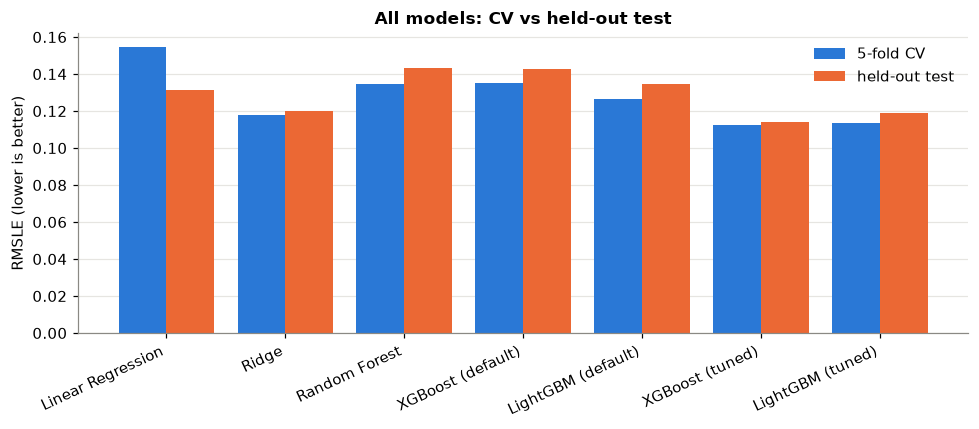

Best model (chosen by CV only): XGBoost (tuned)


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(table))
ax.bar(x - 0.2, table["CV RMSLE"], 0.4, color="#2a78d6", label="5-fold CV")
ax.bar(x + 0.2, table["Test RMSLE"], 0.4, color="#eb6834", label="held-out test")
ax.set_xticks(x, table.index, rotation=25, ha="right")
ax.set_ylabel("RMSLE (lower is better)")
ax.set_title("All models: CV vs held-out test")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Best model (chosen by CV only):", metrics["meta"]["best_model"])

**Insight.**
- Untuned boosters (XGBoost 0.135, LightGBM 0.126 CV RMSLE) are *worse* than Ridge (0.118): boosting is not magic out of the box, defaults overfit 1,166 rows.
- After Optuna tuning (60 trials each) both boosters beat everything: XGBoost 0.1122 and LightGBM 0.1134 CV RMSLE. They are statistically tied
  (fold std ~0.012); XGBoost was selected on CV and nothing was picked from the test set.
- Plain Linear Regression is the weakest and the most unstable (fold std 0.051): with ~250 correlated features it overfits, which is exactly what Ridge's penalty fixes.
- CV and test agree (0.112 vs 0.114) so there is no sign of overfitting to the validation folds.

## 4. Tuned hyperparameters (Optuna, 60 trials each, TPE sampler, seed 42)

In [6]:
pd.DataFrame(metrics["best_params"]).round(4)

,XGBoost,LightGBM
n_estimators,1300.0000,600.0000
learning_rate,0.0300,0.0251
max_depth,2.0000,NaN
min_child_weight,2.0000,NaN
subsample,0.8244,0.7239
colsample_bytree,0.5427,0.3512
reg_alpha,0.0964,0.0076
reg_lambda,0.0045,0.0319
num_leaves,NaN,6.0000
min_child_samples,NaN,6.0000


**Insight.** Both searches settled on **shallow trees** (XGBoost `max_depth=2`, LightGBM `num_leaves=6`), low learning rates and strong
column subsampling (`colsample_bytree` ~0.35-0.55). With ~1,200 rows and many noisy features, simple, heavily-regularised ensembles generalise best.

## 5. Diagnostics on the held-out test set

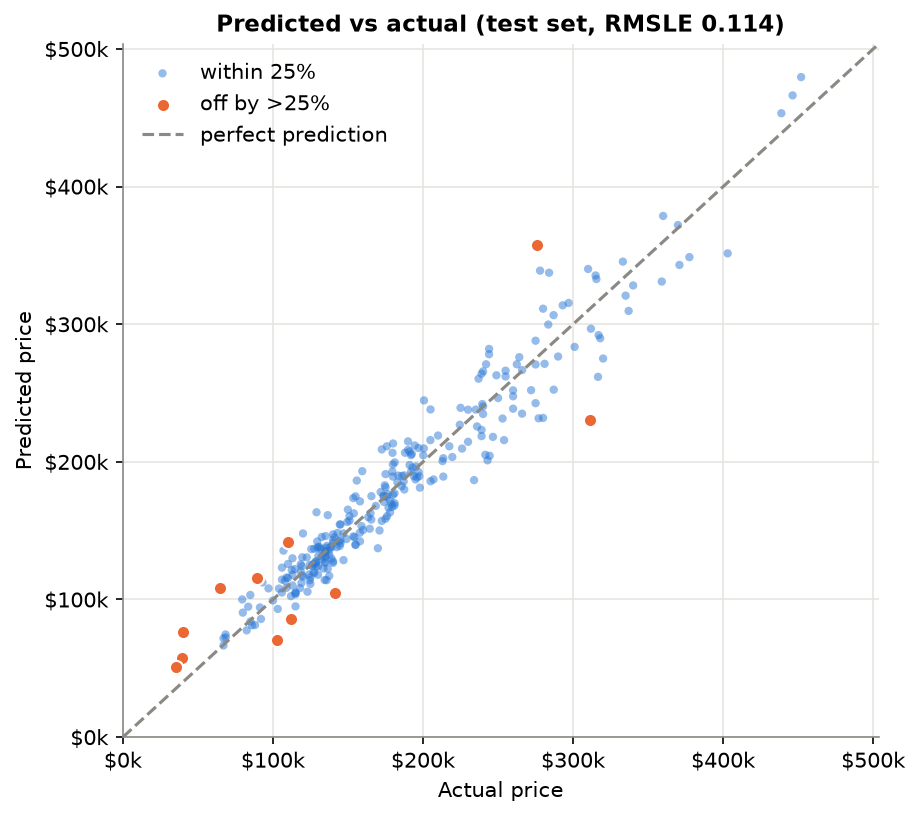

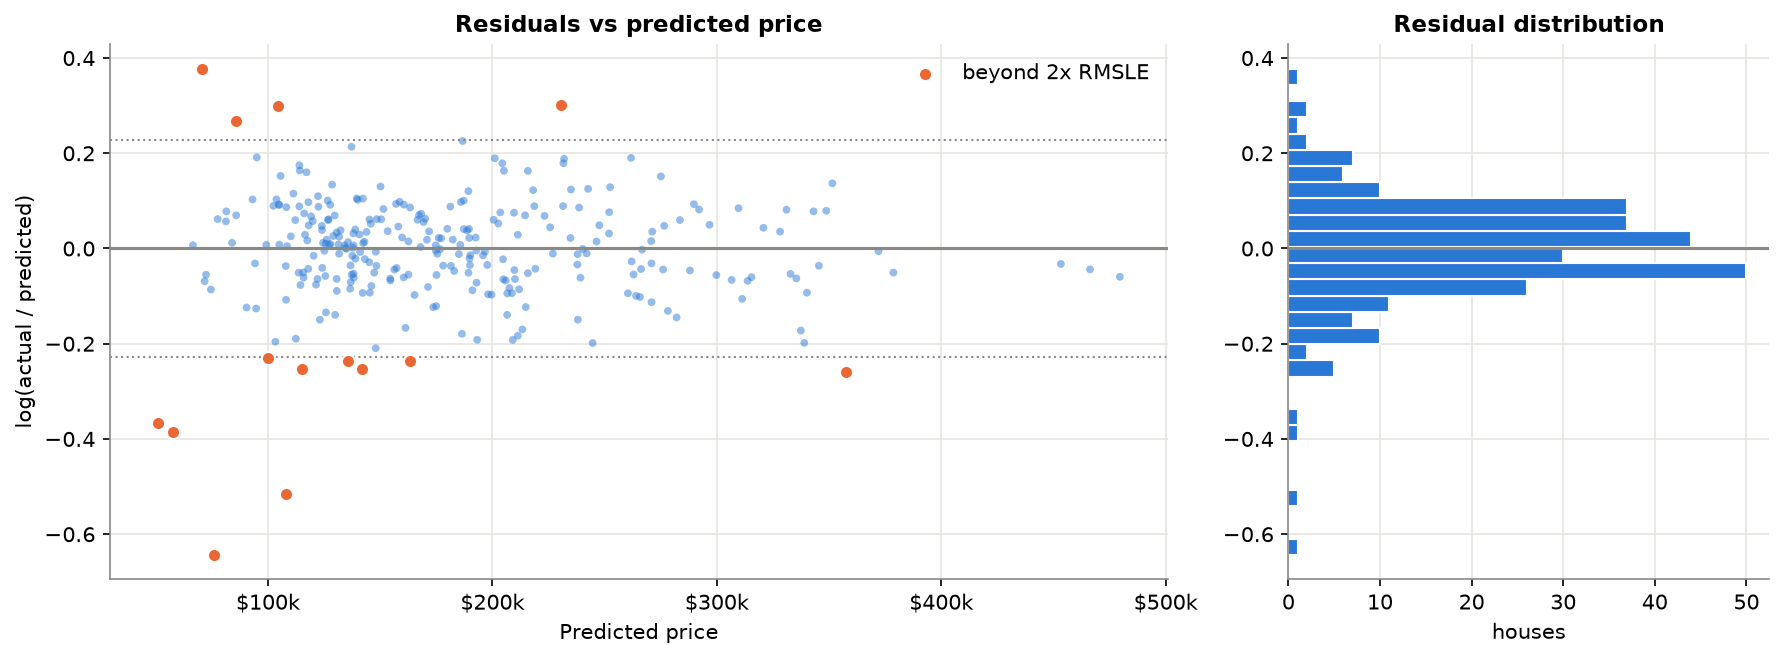

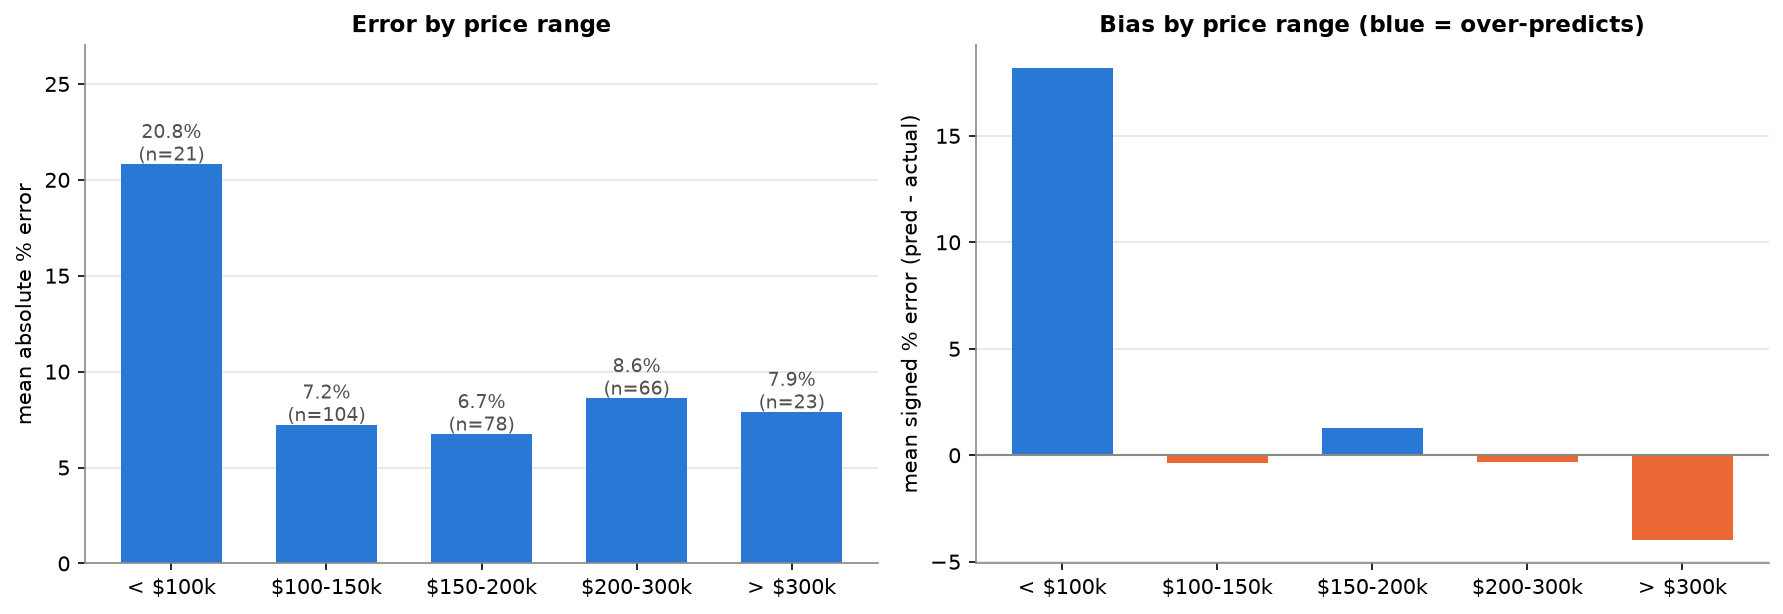

In [7]:
for name in ["pred_vs_actual", "residuals", "error_by_price_band"]:
    display(Image(filename=str(FIGURES_DIR / f"{name}.png"), width=800))

In [8]:
bands = pd.DataFrame(metrics["evaluation"]["error_by_price_band"]).set_index("band")
bands.style.format({"mape": "{:.1f}%", "bias": "{:+.1f}%", "rmsle": "{:.3f}"})

,n,mape,bias,rmsle
band,,,,
< $100k,21,20.8%,+18.2%,0.242
$100-150k,104,7.2%,-0.3%,0.101
$150-200k,78,6.7%,+1.3%,0.083
$200-300k,66,8.6%,-0.3%,0.105
> $300k,23,7.9%,-4.0%,0.103


**Insight.** Points hug the diagonal across the whole range, residuals are centred on zero with no funnel shape (the log target did its job),
and the typical error is ~7%. The exception is the sub-$100k band: 21% average error and a +18% over-prediction bias. Details in section 7.

## 6. Explainability

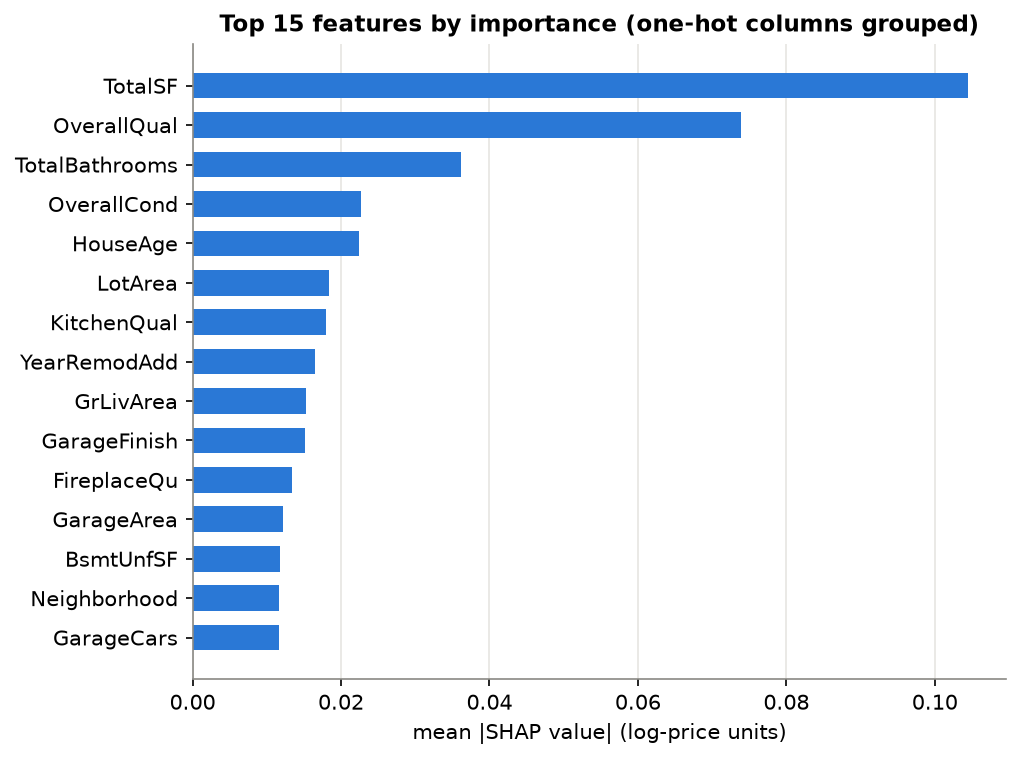

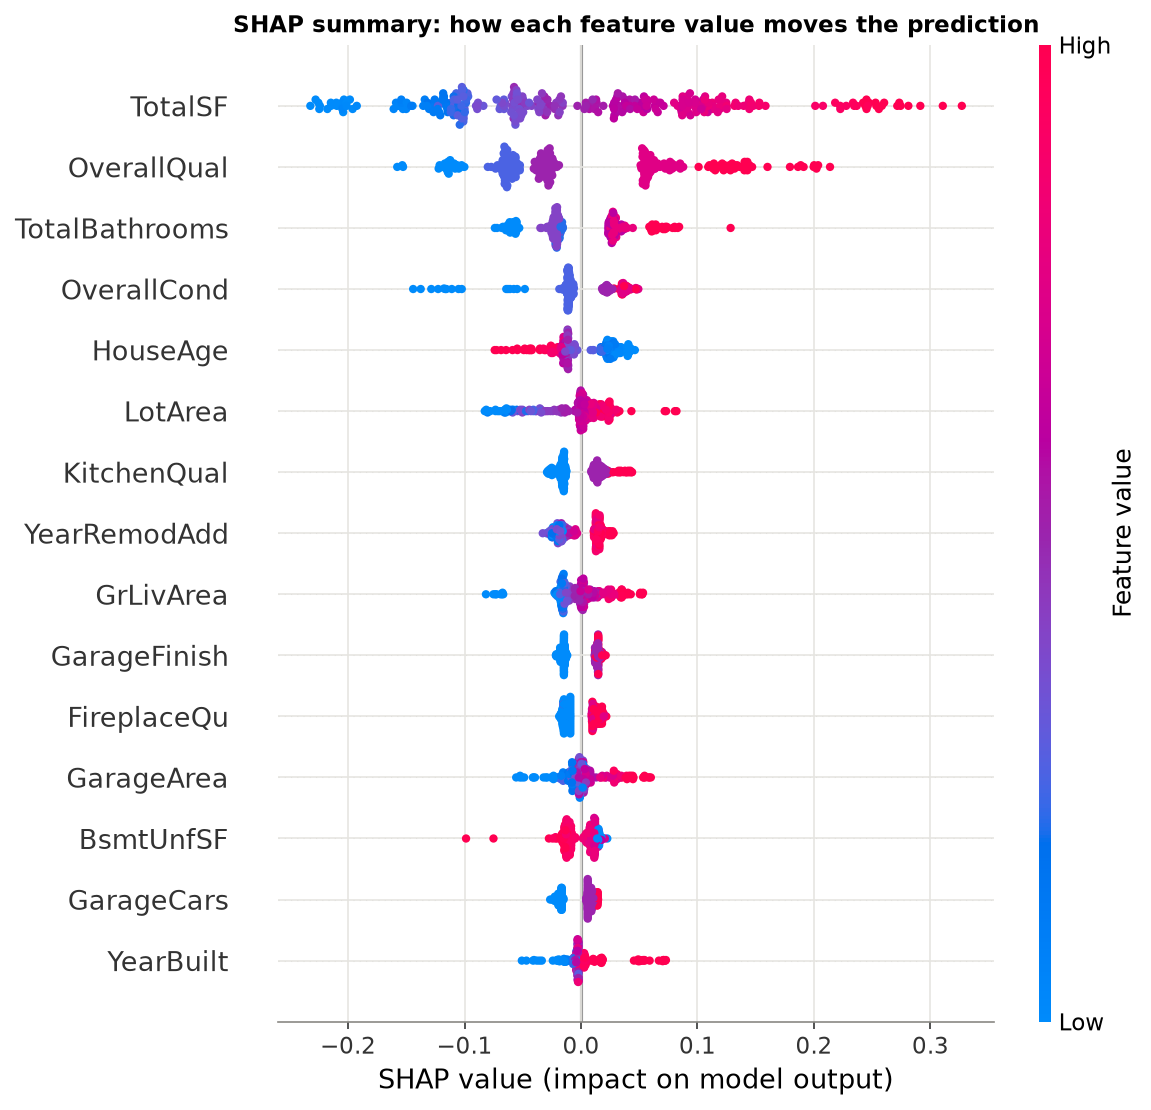

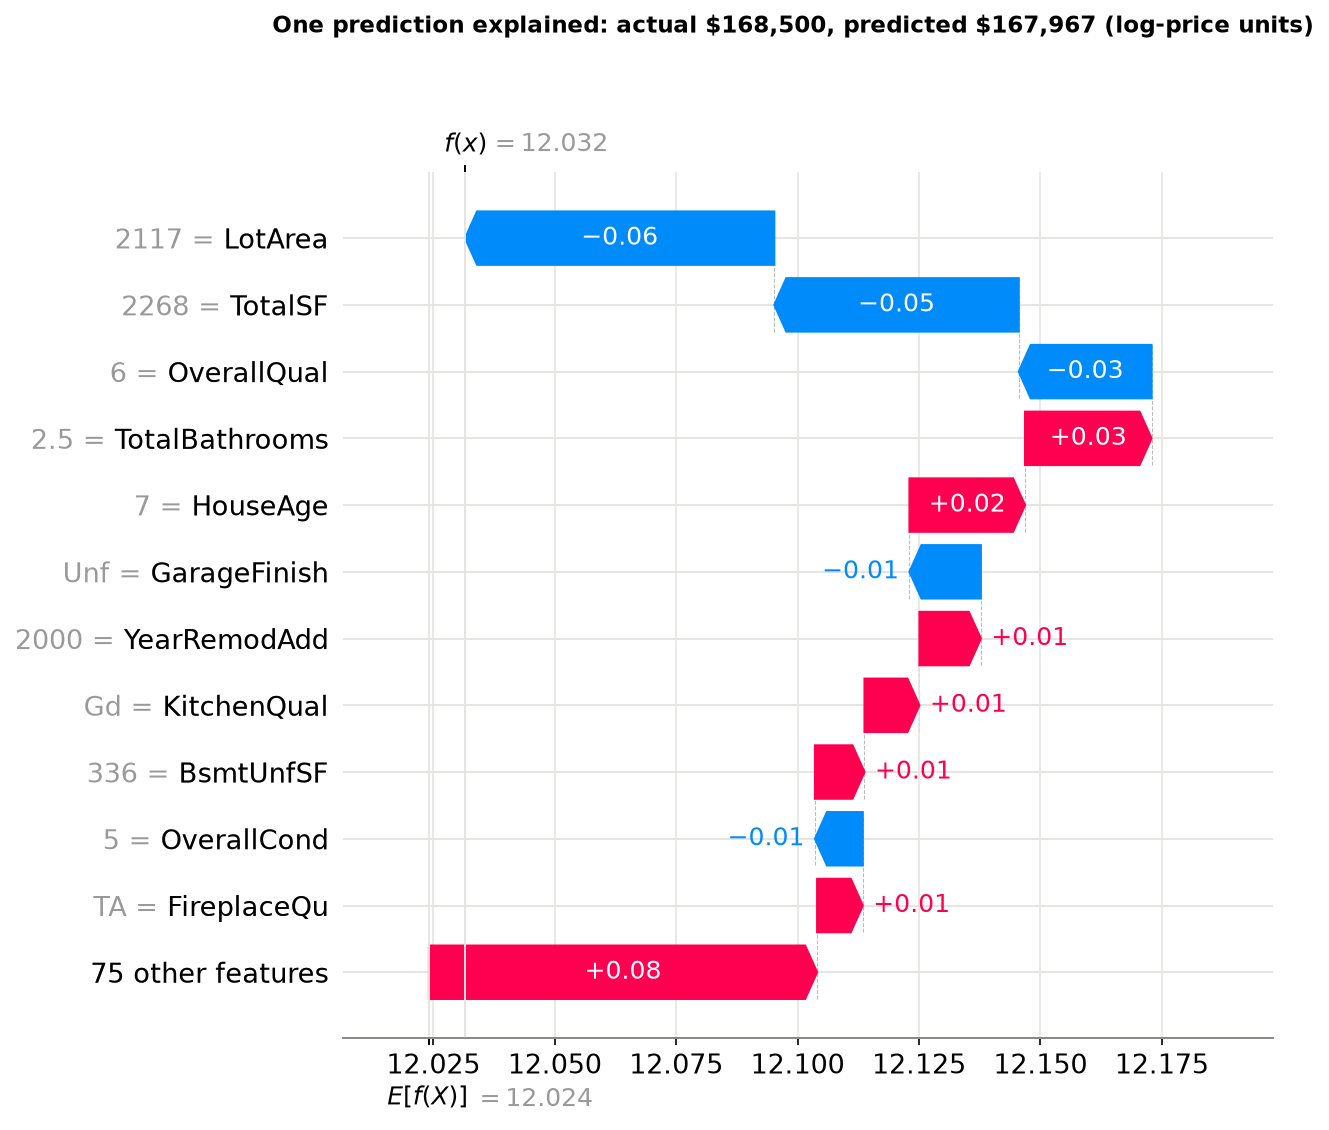

In [9]:
for name in ["feature_importance", "shap_summary", "shap_waterfall"]:
    display(Image(filename=str(FIGURES_DIR / f"{name}.png"), width=700))

**Insight.**
- **Size and quality dominate.** `TotalSF` (our engineered total area) is the #1 feature and `OverallQual` #2, followed by `TotalBathrooms`,
  `OverallCond` and `HouseAge`. Three of the top five are *features we engineered*, which justifies the feature work in Phase 3.
- The SHAP beeswarm shows sensible directions: more area, quality, bathrooms and a newer age all push the price up (red = high feature value on the right),
  while an old house (`HouseAge`, red on the left) pushes it down.
- The waterfall decomposes one real test house (actual $168,500, predicted $167,967) into per-feature log-price contributions: a small lot and a small total
  area pull it below average; extra bathrooms and a young age push it up. SHAP values are additive in *log* price, so they act as multiplicative % effects in dollars.

## Where the model fails, and why

Final model: tuned XGBoost. Held-out test set of 292 houses: RMSLE 0.114, median absolute error 6.3%,
75.7% of predictions within 10% of the true price. Those are good averages, but the errors are not spread evenly.

**1. The cheapest houses (under $100k).** They are 7% of the test set but cause **32% of the total squared log error**.
Mean absolute error is 20.8% (vs 6.7-8.6% in every other price band) and the model *over*-predicts them by 18% on average.
Only 93 of the 1,166 training houses sell for under $100k, and what separates a $40k house from a $75k house
(interior state, deferred maintenance, distressed sale) is mostly not in the columns. The model regresses
toward the average. Worst case: a 1920 `IDOTRR` house, 1,317 sq ft, sold for $40,000, predicted $76,105 (+90%).

**2. Low-quality and old houses.** Houses rated `OverallQual <= 4` are 10% of the test set but 41% of the error
(RMSLE 0.233 vs 0.114 overall). Houses built before 1950 are 23% of the set and 48% of the error (RMSLE 0.165).
Two houses with the same rating and age can be a fixer-upper or a lovingly renovated home, and `OverallQual`
and `OverallCond` are coarse 1-10 human ratings with no photos or renovation details behind them.

**3. Unusual sales.** Non-`Normal` sale conditions (abnormal sale, family sale, allocation...) are 21% of houses but 28% of the
error; abnormal sales have RMSLE 0.160 vs 0.109 for normal ones. In a foreclosure or family transfer the price reflects the
*circumstances*, which no property feature can reveal.

**4. The expensive tail (over $300k).** Only mild: about 4% under-prediction on average across 23 houses. Tree models cannot
extrapolate beyond what they saw, so rare, very large or very luxurious houses are pulled down toward the bulk of the data.

**5. The metric is dominated by a few houses.** The 10 worst predictions (3.4% of the test set) account for **39%** of the squared
log error. Without them the RMSLE would be 0.091 rather than 0.114. This is why one lucky or unlucky test sample moves the score,
and why the cross-validated figure (0.112 +/- 0.012 across folds) is as important as the single test number.

**Sensitivity to the outlier decision.** Two partial-sale mega-houses (Ids 524 and 1299: 4,676 and 5,642 sq ft sold for $184,750
and $160,000) were removed before the split, as the dataset's author recommends. The model predicts roughly $706k and $781k for them,
which is what their size implies. If they were left in the test set the RMSLE would be **0.166** instead of 0.114. The headline
number is therefore valid for "ordinary, fully-built houses", not for sales where the price is disconnected from the property.

**The 80% prediction band is uniform.** It is +/-11.5% for every house and covers 78.8% of the test houses overall, but the real
uncertainty is much larger for cheap, old and unusual sales than for a typical mid-range house.

### What would improve it
- More low-price examples, or features about condition and renovation (photos, permit history).
- A robust loss (Huber / quantile) or a separate model for the low end.
- Segment-aware (conformal) prediction intervals instead of one uniform band.
- Neighborhood-level price trends, since this data covers only 2006-2010 in one city.


In [10]:
pd.DataFrame(metrics["evaluation"]["worst_10"])

,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondition,actual,predicted,pct_error
0,IDOTRR,4,1317,1920,Normal,40000.0,76105.0,90.3
1,OldTown,4,968,1927,Normal,64500.0,108083.0,67.6
2,BrkSide,1,334,1946,Normal,39300.0,57750.0,46.9
3,IDOTRR,4,1178,1900,Abnorml,102776.0,70457.0,-31.4
4,IDOTRR,2,480,1949,Abnorml,35311.0,50983.0,44.4
5,Crawfor,7,1954,1939,Normal,311500.0,230488.0,-26.0
6,Gilbert,4,864,1951,Normal,141000.0,104471.0,-25.9
7,Edwards,4,960,1956,Abnorml,112000.0,85697.0,-23.5
8,CollgCr,8,2574,2007,Partial,276000.0,357587.0,29.6
9,OldTown,4,1131,1937,Alloca,89471.0,115349.0,28.9


## Conclusion
- Final model: **tuned XGBoost**, trained on `log1p(price)` behind a leakage-free preprocessing pipeline.
- **Held-out test RMSLE 0.114** (CV 0.112 +/- 0.012), RMSE $19.3k, MAE $14.2k, R2 0.933.
- This is *better* than the 0.12-0.14 range we expected. It is real (no leakage; selection by CV only) but depends on the documented outlier removal
  (0.166 if the two partial-sale outliers stay in the test set) and on a small 292-house test set.
- Weak spots: cheap, old, low-quality and unusual-sale houses.